In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob
import numpy as np

# Настройка стиля графиков
plt.style.use('seaborn-v0_8')
plt.rcParams['figure.figsize'] = (15, 10)

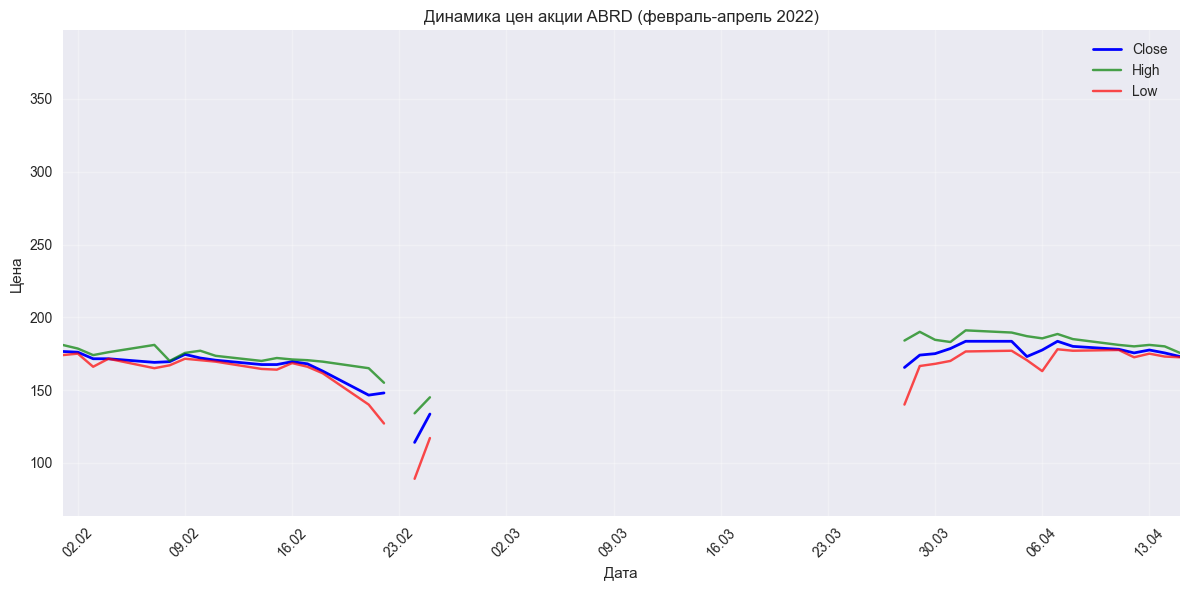

In [ ]:
ticket = "moex_data/ABRD.csv"
df = pd.read_csv(ticket)
df['TRADEDATE'] = pd.to_datetime(df['TRADEDATE'])
df = df.sort_values('TRADEDATE')

stock_name = os.path.basename(ticket).replace('.csv', '')

# Создаем один график
plt.figure(figsize=(12, 6))

# График цен (OHLC)
plt.plot(df['TRADEDATE'], df['CLOSE'], label='Close', linewidth=2, color='blue')
plt.plot(df['TRADEDATE'], df['HIGH'], label='High', alpha=0.7, color='green')
plt.plot(df['TRADEDATE'], df['LOW'], label='Low', alpha=0.7, color='red')

# Устанавливаем ограничения по датам
feb_2022_start = pd.to_datetime('2022-02-01')
feb_2022_end = pd.to_datetime('2022-04-15')
plt.xlim([feb_2022_start, feb_2022_end])

# Форматирование дат
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d.%m'))
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.DayLocator(interval=7))
plt.xticks(rotation=45)

plt.title(f'Динамика цен акции {stock_name} (февраль-апрель 2022)')
plt.ylabel('Цена')
plt.xlabel('Дата')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# На примере акций АбрауДюрсо пропущены значения по датам за конец февраля - март 2022. 
# Связано это с приостановкой торгов. По другим признакам пропусков нет.

CLOSE: 283 выбросов
VOLUME: 277 выбросов
VALUE: 288 выбросов


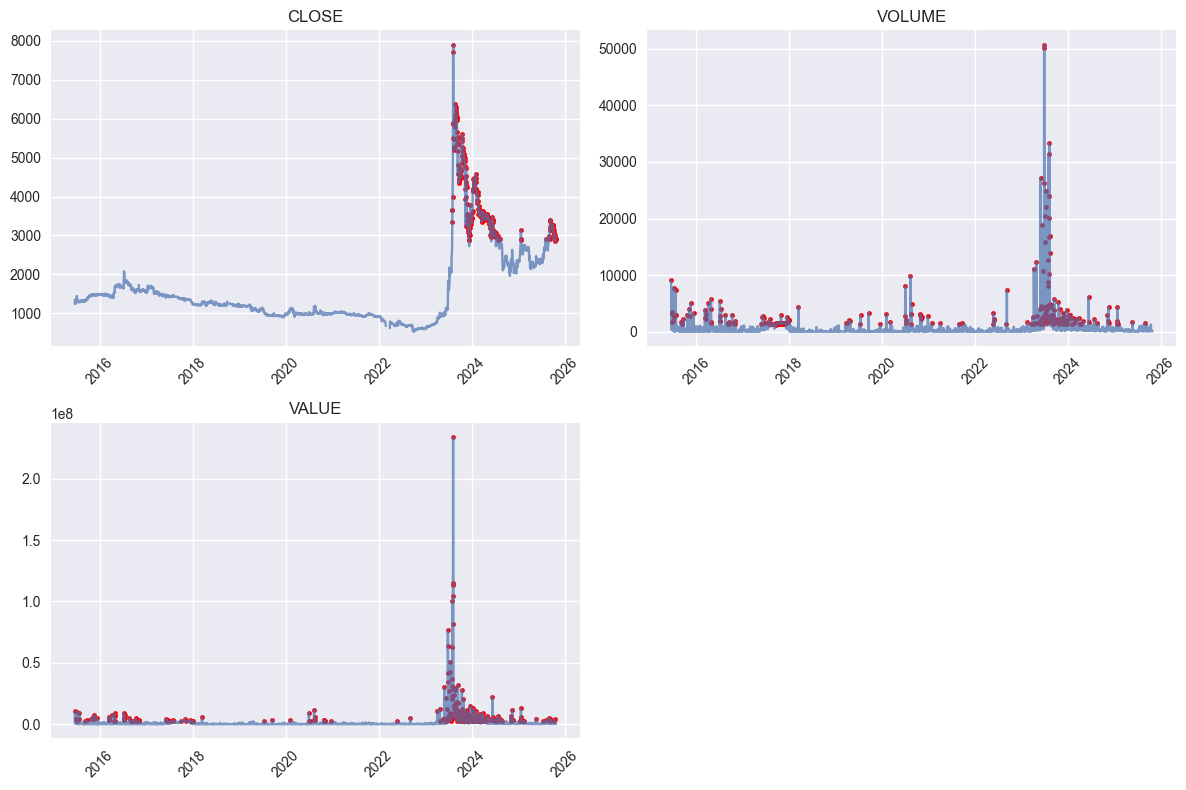

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("moex_data/TNSE.csv")
df['TRADEDATE'] = pd.to_datetime(df['TRADEDATE'])

# Поиск выбросов
def find_outliers(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    return (series < Q1 - 1.5*IQR) | (series > Q3 + 1.5*IQR)

# Анализ основных полей
for col in ['CLOSE', 'VOLUME', 'VALUE']:
    if col in df.columns:
        outliers = find_outliers(df[col])
        print(f"{col}: {outliers.sum()} выбросов")

# Простая визуализация
plt.figure(figsize=(12, 8))

for i, col in enumerate(['CLOSE', 'VOLUME', 'VALUE'], 1):
    plt.subplot(2, 2, i)
    outliers = find_outliers(df[col])
    plt.plot(df['TRADEDATE'], df[col], alpha=0.7)
    plt.scatter(df['TRADEDATE'][outliers], df[col][outliers], color='red', s=10)
    plt.title(col)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()